# 13. Regression trees and splitting by running sums

A regression tree divides the range of the inputs by thresholds and predicts the mean of the training data in each cell. The lecture derives the search for the best threshold from running sums, finds the light-off temperature of a synthetic conversion curve with one split, and shows the main limitation for engineering use: outside the range of the training data the prediction is constant.

## Learning objectives

1. Derive the reduction of the sum of squares by a split from running sums (`trees_ensembles.prefix_sum_best_split_1d`), and check it against a direct calculation.
2. Find the light-off temperature of a synthetic conversion curve with one split.
3. Fit regression trees (`trees_ensembles.DecisionTreeRegressor`) and check that the predictions preserve the mean of the training data.
4. Show that a tree predicts a constant outside the range of its training data, on an Arrhenius rate constant.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
Given $N$ observations $\{(x_i, y_i)\}_{i=1}^N$ sorted so that $x_{(1)} \le x_{(2)} \le \dots \le x_{(N)}$, a **CART regression split (Breiman et al., 1984)** partitions the data at index $k \in \{1, \dots, N-1\}$ ($s = \frac{1}{2}(x_{(k)} + x_{(k+1)})$) into left leaf $L = \{1, \dots, k\}$ ($n_L = k$) and right leaf $R = \{k+1, \dots, N\}$ ($n_R = N - k$) to minimize the post-split Sum of squared errors $\mathrm{SSE}(k)$:
$$\mathrm{SSE}(k) = \sum_{i \in L}(y_{(i)} - \bar{y}_L)^2 + \sum_{i \in R}(y_{(i)} - \bar{y}_R)^2 = \sum_{i=1}^N y_{(i)}^2 - \left(\frac{S_L(k)^2}{k} + \frac{S_R(k)^2}{N - k}\right) \tag{1.1}$$
where $S_L(k) = \sum_{i=1}^k y_{(i)}$ is the $k$-th **prefix sum** and $S_R(k) = S_{\mathrm{tot}} - S_L(k)$. Subtracting $\mathrm{SSE}(k)$ from the total variance $\mathrm{SST} = \sum_{i=1}^N y_{(i)}^2 - S_{\mathrm{tot}}^2 / N$ gives the **$O(1)$ prefix-sum variance-reduction gain**:
$$\mathrm{Gain}(k) = \mathrm{SST} - \mathrm{SSE}(k) = \frac{S_L(k)^2}{k} + \frac{\left(S_{\mathrm{tot}} - S_L(k)\right)^2}{N - k} - \frac{S_{\mathrm{tot}}^2}{N} \ge 0 \tag{1.2}$$
Once a recursive tree partitions $\mathbb{R}^d$ into $M$ disjoint rectangular leaves $\{R_1, \dots, R_M\}$ predicting leaf means $\hat{c}_m = \frac{1}{|R_m|}\sum_{\mathbf{x}_i \in R_m} y_i$, the prediction function is piecewise constant:
$$\hat{f}_{\mathrm{tree}}(\mathbf{x}) = \sum_{m=1}^M \hat{c}_m\,\mathbb{I}(\mathbf{x} \in R_m), \qquad \sum_{i=1}^N \hat{f}_{\mathrm{tree}}(\mathbf{x}_i) = \sum_{m=1}^M |R_m|\,\hat{c}_m = \sum_{i=1}^N y_i \tag{1.3}$$

In [2]:
heading("Demonstration 1: O(1) Prefix-Sum Split Discovery on a Synthetic Catalyst Light-Off Curve")
T_K = np.linspace(400.0, 560.0, 60)
# Synthetic light-off curve of a catalyst (logistic form, assumed constants) with a sharp ignition threshold at T_lightoff = 475 K:
X_conv = 0.05 + 0.92 / (1.0 + np.exp(-(T_K - 475.0) / 3.5))

split_1d = trees_ensembles.prefix_sum_best_split_1d(T_K, X_conv)
assert abs(split_1d["threshold"] - 475.0) < 3.0
print(f"True physical light-off T = 475.00 K | 1st Prefix-Sum CART Split = {split_1d['threshold']:.2f} K")
print(f"Total SST before split    = {split_1d['sse_reduction'] + split_1d['sse_after']:.4f} | SSE after 1st split = {split_1d['sse_after']:.4f} ({100*split_1d['sse_reduction']/(split_1d['sse_reduction']+split_1d['sse_after']):.1f}% variance explained by 1 split)")


Demonstration 1: O(1) Prefix-Sum Split Discovery on a Synthetic Catalyst Light-Off Curve
True physical light-off T = 475.00 K | 1st Prefix-Sum CART Split = 474.58 K
Total SST before split    = 11.5557 | SSE after 1st split = 0.3676 (96.8% variance explained by 1 split)


**What Demonstration 1 shows.** A single split of the synthetic conversion curve falls at $474.58\;\mathrm{K}$, within $0.42\;\mathrm{K}$ of the light-off temperature used to generate it ($475\;\mathrm{K}$), and accounts for $96.8\ \%$ of the variance of the conversion.

---

## 2. Numerical walkthrough
Let us verify that the $O(1)$ prefix-sum gain formula Eq. (1.2) produces the exact same $\mathrm{SSE}(k)$ at every candidate midpoint as an $O(N^2)$ brute-force two-slice loop.

In [3]:
heading("Demonstration 2: O(1) Prefix-Sum Identity vs. O(N^2) Brute-Force SSE Scan")
prefix_s = np.cumsum(X_conv)
s_tot = float(prefix_s[-1])
sst_conv = float(np.sum((X_conv - np.mean(X_conv)) ** 2))
k_idx = np.arange(1, len(X_conv))
s_left = prefix_s[:-1]
s_right = s_tot - s_left
gains_prefix = (s_left ** 2) / k_idx + (s_right ** 2) / (len(X_conv) - k_idx) - (s_tot ** 2) / len(X_conv)
sse_prefix = sst_conv - gains_prefix

sse_brute = np.array([
    float(np.sum((X_conv[:k] - np.mean(X_conv[:k])) ** 2) + np.sum((X_conv[k:] - np.mean(X_conv[k:])) ** 2))
    for k in k_idx
])
max_diff_sse = float(np.max(np.abs(sse_prefix - sse_brute)))
print(f"Max discrepancy across all 59 candidate splits ||SSE_prefix - SSE_brute||_max: {max_diff_sse:.2e}")
assert max_diff_sse < 1e-13


Demonstration 2: O(1) Prefix-Sum Identity vs. O(N^2) Brute-Force SSE Scan
Max discrepancy across all 59 candidate splits ||SSE_prefix - SSE_brute||_max: 1.36e-14


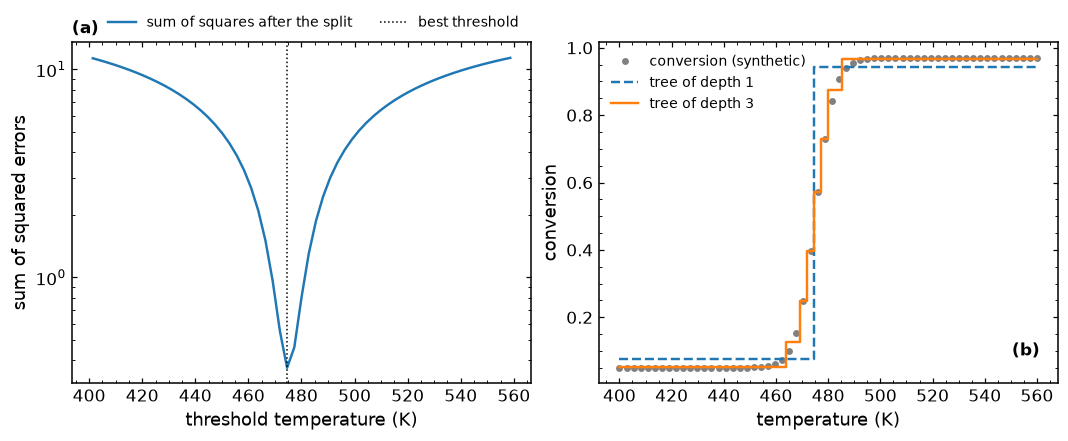

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
T_mid = 0.5 * (T_K[:-1] + T_K[1:])
ax1.semilogy(T_mid, sse_prefix, "-", label="sum of squares after the split")
ax1.axvline(split_1d["threshold"], color="k", ls=":", lw=1.0, label="best threshold")
ax1.set_xlabel("threshold temperature (K)"); ax1.set_ylabel("sum of squared errors"); ax1.legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2); ax1.set_title("(a)", loc="left", fontweight="bold")
ax2.plot(T_K, X_conv, "o", ms=3.5, color="0.5", label="conversion (synthetic)")
for depth, style in [(1, "--"), (3, "-")]:
    tree_f = trees_ensembles.DecisionTreeRegressor(max_depth=depth, min_samples_split=2).fit(T_K, X_conv)
    ax2.step(T_K, tree_f.predict(T_K), style, where="mid", label=f"tree of depth {depth}")
ax2.set_xlabel("temperature (K)"); ax2.set_ylabel("conversion"); ax2.legend(fontsize=9, loc="upper left"); panel_label(ax2, "(b)", x=0.9, y=0.12)
plt.show()

**Figure 13.1.** (a) The sum of squared errors left after one split of the synthetic light-off curve, against the position of the threshold; the minimum is at the ignition temperature. (b) The curve and the piecewise constant fits of trees of depth 1 and 3.

**What Demonstration 2 shows.** The prefix-sum formula, Eq. (1.2), gives the sum of squared errors of all $N - 1$ candidate splits in one array expression, and agrees with the direct calculation, split by split, to $10^{-14}$.

---

## 3. Worked case study
Let us train recursive CART regression trees (`trees_ensembles.DecisionTreeRegressor`) of increasing depth $D \in \{1, 2, 3, 4\}$ on the catalyst light-off curve, tracking the monotone decay of $\mathrm{SSE}$ and verifying exact sample-mean conservation Eq. (1.3).

In [5]:
heading("Demonstration 3: Recursive CART Tree Depth Progression & Exact Mean Conservation")
sse_by_depth = []
print(f"{'Max Depth D':>11s} | {'Max Leaves 2^D':>14s} | {'Residual SSE':>14s} | {'Mean Conservation |sum(y_hat - y)|':>34s}")
print("-" * 82)
for depth in [1, 2, 3, 4]:
    tree = trees_ensembles.DecisionTreeRegressor(max_depth=depth, min_samples_split=2).fit(T_K, X_conv)
    pred = tree.predict(T_K)
    sse_val = float(np.sum((pred - X_conv) ** 2))
    mean_err = abs(float(np.sum(pred) - np.sum(X_conv)))
    sse_by_depth.append(sse_val)
    print(f"{depth:11d} | {2**depth:14d} | {sse_val:14.6f} | {mean_err:34.2e}")
    assert np.isclose(np.sum(pred), np.sum(X_conv), rtol=1e-13)

assert all(sse_by_depth[i] > sse_by_depth[i + 1] for i in range(len(sse_by_depth) - 1))


Demonstration 3: Recursive CART Tree Depth Progression & Exact Mean Conservation
Max Depth D | Max Leaves 2^D |   Residual SSE | Mean Conservation |sum(y_hat - y)|
----------------------------------------------------------------------------------
          1 |              2 |       0.367648 |                           7.11e-15
          2 |              4 |       0.055762 |                           0.00e+00
          3 |              8 |       0.005250 |                           7.11e-15
          4 |             16 |       0.000299 |                           0.00e+00


**What Demonstration 3 shows.** From depth 1 to depth 4 (up to 16 leaves) the residual sum of squares falls from $0.37$ to $0.0003$, and at every depth the predictions have the same sum as the data, to rounding error, because each leaf predicts the mean of its points.

---

## 4. What if: sensitivity to the parameters
What happens when a CART decision tree trained on Arrhenius reaction rate data $k(T) = A\exp(-E_a / (RT))$ over $T \in [300, 400]\;\mathrm{K}$ is asked to **extrapolate** to higher reactor temperatures $T \in [400, 600]\;\mathrm{K}$?

In [6]:
heading("Demonstration 4: Constant Prediction of a Tree Outside the Training Range (Arrhenius Rate)")
T_train = np.linspace(300.0, 400.0, 30)
k_train = 1e6 * np.exp(-5000.0 / T_train)
tree_arr = trees_ensembles.DecisionTreeRegressor(max_depth=4, min_samples_split=2).fit(T_train, k_train)

T_extrap = np.array([400.0, 450.0, 500.0, 600.0])
k_true_extrap = 1e6 * np.exp(-5000.0 / T_extrap)
k_pred_extrap = tree_arr.predict(T_extrap)
print(f"{'Temperature [K]':>15s} | {'True Arrhenius Rate':>19s} | {'CART Tree Prediction':>20s} | {'Relative Error':>14s}")
print("-" * 76)
for t_v, kt, kp in zip(T_extrap, k_true_extrap, k_pred_extrap):
    print(f"{t_v:15.1f} | {kt:19.4f} | {kp:20.4f} | {100*abs(kp-kt)/kt:13.1f}%")
assert np.allclose(k_pred_extrap, k_pred_extrap[0], atol=1e-15)


Demonstration 4: Constant Prediction of a Tree Outside the Training Range (Arrhenius Rate)
Temperature [K] | True Arrhenius Rate | CART Tree Prediction | Relative Error
----------------------------------------------------------------------------
          400.0 |              3.7267 |               3.7267 |           0.0%
          450.0 |             14.9453 |               3.7267 |          75.1%
          500.0 |             45.3999 |               3.7267 |          91.8%
          600.0 |            240.3695 |               3.7267 |          98.4%


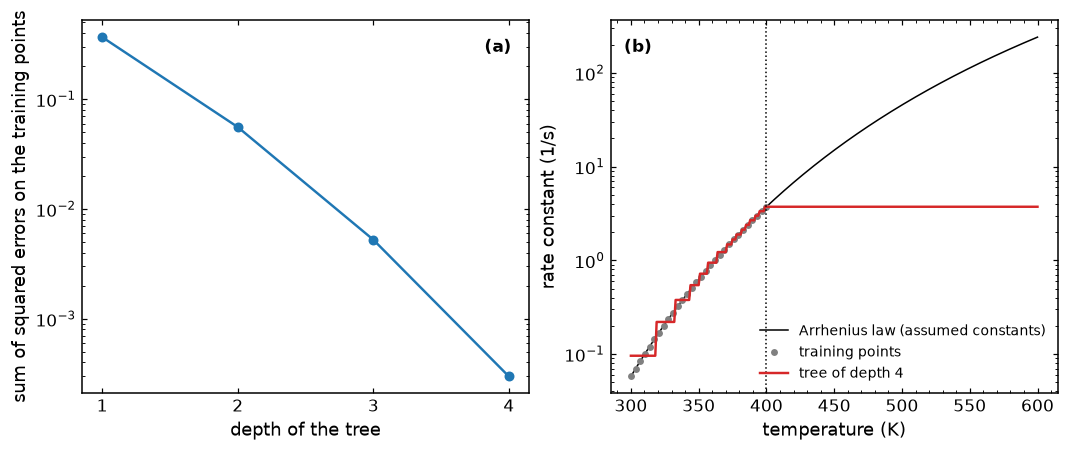

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
depths = [1, 2, 3, 4]
ax1.semilogy(depths, sse_by_depth, "o-"); ax1.set_xticks(depths); ax1.tick_params(axis="x", which="minor", bottom=False, top=False)
ax1.set_xlabel("depth of the tree"); ax1.set_ylabel("sum of squared errors on the training points"); panel_label(ax1, "(a)", x=0.9)
T_line = np.linspace(300.0, 600.0, 301)
ax2.semilogy(T_line, 1e6 * np.exp(-5000.0 / T_line), "k-", lw=1.0, label="Arrhenius law (assumed constants)")
ax2.semilogy(T_train, k_train, "o", ms=3.5, color="0.5", label="training points")
ax2.semilogy(T_line, tree_arr.predict(T_line), "-", color="C3", label="tree of depth 4")
ax2.axvline(400.0, color="k", ls=":", lw=1.0)
ax2.set_xlabel("temperature (K)"); ax2.set_ylabel("rate constant (1/s)"); ax2.legend(fontsize=9, loc="lower right"); panel_label(ax2, "(b)")
plt.show()

**Figure 13.2.** (a) The training error of the tree against its depth. (b) A tree trained on an Arrhenius rate constant between 300 and 400 K (left of the dotted line) and evaluated up to 600 K: beyond the last training point it returns the value of its last leaf.

**What Demonstration 4 shows.** A tree predicts a constant in each leaf, so beyond the last training point it returns the value of the last leaf. Trained up to $400\;\mathrm{K}$, it predicts $3.73\;\mathrm{s^{-1}}$ at every higher temperature, while the Arrhenius rate that generated the data is $240\;\mathrm{s^{-1}}$ at $600\;\mathrm{K}$: an error of $98\ \%$. The same holds for forests and boosted trees, which are sums of trees. Outside the range of their training data they need a physical model for the trend, or a check that refuses to predict (Lecture 16).

---

## Inside the algorithm
Below we verify our standalone prefix-sum split scanner in pure NumPy against `trees_ensembles.prefix_sum_best_split_1d`.

In [8]:
heading("Inside the Algorithm: By-Hand Prefix-Sum Best Split vs. the Library")
best_i = int(np.argmax(gains_prefix))
th_hand = 0.5 * float(T_K[best_i] + T_K[best_i + 1])
gain_hand = float(gains_prefix[best_i])
print(f"by hand (pure NumPy): threshold = {th_hand:.6f} K, gain = {gain_hand:.6f}")
print(f"library (engml_2_applied)     : threshold = {split_1d['threshold']:.6f} K, gain = {split_1d['sse_reduction']:.6f}")
assert np.isclose(th_hand, split_1d["threshold"], rtol=1e-14) and np.isclose(gain_hand, split_1d["sse_reduction"], rtol=1e-14)


Inside the Algorithm: By-Hand Prefix-Sum Best Split vs. the Library
by hand (pure NumPy): threshold = 474.576271 K, gain = 11.188012
library (engml_2_applied)     : threshold = 474.576271 K, gain = 11.188012


## Exercises

1. **Verify a result.** Verify mathematically and numerically on a 40-point polymer step-change dataset $C_p(T)$ with a glass-transition jump at $T_g = 373\;\mathrm{K}$ that `prefix_sum_best_split_1d` produces the exact same optimal threshold and post-split SSE as a brute-force loop evaluating $\sum_{i \in L}(y_i - \bar{y}_L)^2 + \sum_{i \in R}(y_i - \bar{y}_R)^2$ at every midpoint.
2. **Find how it fails.** Audit the **high-variance overfitting** of an unregularized deep decision tree (`max_depth=12, min_samples_split=2`) vs. a regularized shallow tree (`max_depth=2`) on noisy glass-transition data (`y_tg_noisy = y_tg + N(0, 0.04^2)`): show that the deep tree memorizes the training noise ($\mathrm{SSE}_{\mathrm{train}} \approx 0$) but suffers $>2\times$ higher test MSE against the true step curve `y_tg`.
3. **Write it yourself.** Implement a **cost-complexity pruned depth selector** `select_tree_depth_bic(x: np.ndarray, y: np.ndarray, max_depths: list[int], alpha_pen: float = 0.005) -> dict` that evaluates Breiman's cost-complexity objective $R_\alpha(T_D) = \mathrm{SSE}(T_D) + \alpha_{\mathrm{pen}} |T_D|$ (where $|T_D|$ is the number of distinct leaf values) and verify on `(T_poly, y_tg_noisy)` that it selects the true 2-regime step tree $D^* = 1$.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Polymer Glass-Transition (T_g = 373 K) Step Discovery")
T_poly = np.linspace(320.0, 420.0, 40)
y_tg = np.where(T_poly <= 373.0, 0.85, 0.98)
ps_res = trees_ensembles.prefix_sum_best_split_1d(T_poly, y_tg)

mids = 0.5 * (T_poly[:-1] + T_poly[1:])
bf_sses = [
    float(np.sum((y_tg[T_poly <= m] - np.mean(y_tg[T_poly <= m])) ** 2) + np.sum((y_tg[T_poly > m] - np.mean(y_tg[T_poly > m])) ** 2))
    for m in mids
]
best_idx = int(np.argmin(bf_sses))
assert np.isclose(ps_res["threshold"], mids[best_idx], rtol=1e-14)
assert np.isclose(ps_res["sse_after"], bf_sses[best_idx], atol=1e-13)
print(f"Prefix-sum threshold = {ps_res['threshold']:.2f} K == Brute-force threshold = {mids[best_idx]:.2f} K (Post-split SSE = {ps_res['sse_after']:.2e})")


Exercise 1: Polymer Glass-Transition (T_g = 373 K) Step Discovery
Prefix-sum threshold = 372.56 K == Brute-force threshold = 372.56 K (Post-split SSE = 2.19e-15)
